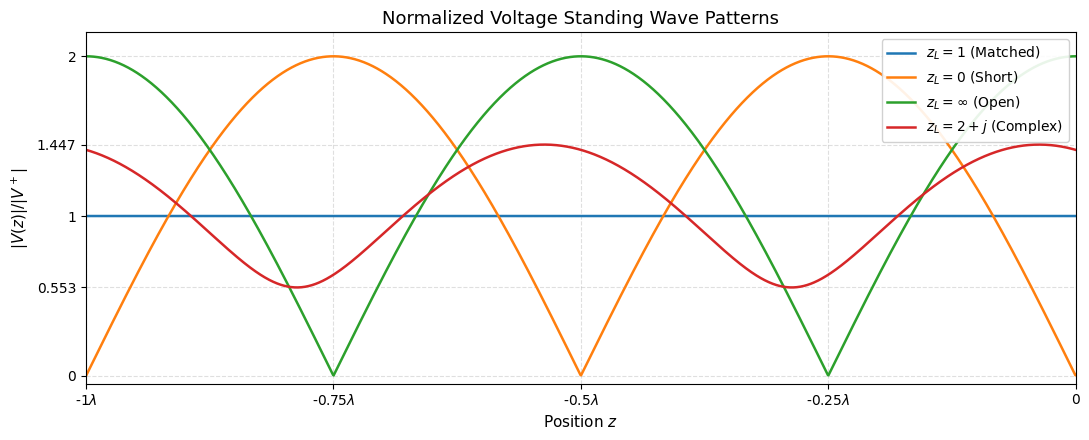

<Figure size 640x480 with 0 Axes>

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# setup
wavelength = 1e-2 # 1cm
c = 3e8
k = 2*np.pi/wavelength
z_nls = [1+0j, 0, np.inf, 2+1j]
z_nls = np.array(z_nls)
z = np.linspace(-wavelength*1.5, wavelength*1, 5000)

# handle the infinity in z_nl
with np.errstate(invalid='ignore'):
  gamma_ls = np.where(np.isinf(z_nls), 1+0j, (z_nls - 1)/(z_nls + 1))

labels = [
    r'$z_L = 1$ (Matched)',
    r'$z_L = 0$ (Short)',
    r'$z_L = \infty$ (Open)',
    r'$z_L = 2 + j$ (Complex)'
]

plt.figure(figsize=(11, 4.5))
y_ticks = [1.0]

# calculate and plot
for gamma, label in zip(gamma_ls, labels):
  if gamma == np.inf:
    v_norm = np.abs(1+np.exp(2j*k*z))
  else:
    v_norm = np.abs(1+gamma*np.exp(2j*k*z))

  z_lam = z / wavelength
  plt.plot(z_lam, v_norm, linewidth=1.8, label=label)

  if np.abs(gamma) > 1e-6:
    y_ticks.extend([1 + np.abs(gamma), 1 - np.abs(gamma)])

x_ticks = np.arange(-1.0, 0.01, 0.25)
x_labels = ['0' if np.isclose(val, 0) else f'{val:g}' + r'$\lambda$' for val in x_ticks]
y_ticks = np.unique(np.round(y_ticks, 3))

plt.xticks(x_ticks, x_labels, fontsize=10)
plt.yticks(y_ticks, [f'{val:g}' for val in y_ticks], fontsize=10)

plt.xlim(-1.0, 0.0)
plt.ylim(-0.05, 2.15)
plt.xlabel(r'Position $z$', fontsize=11)
plt.ylabel(r'$|V(z)| / |V^+|$', fontsize=11)
plt.title('Normalized Voltage Standing Wave Patterns', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper right', fontsize=10, framealpha=0.9)
plt.tight_layout()
plt.show()
plt.savefig('figure1.svg', format='svg')


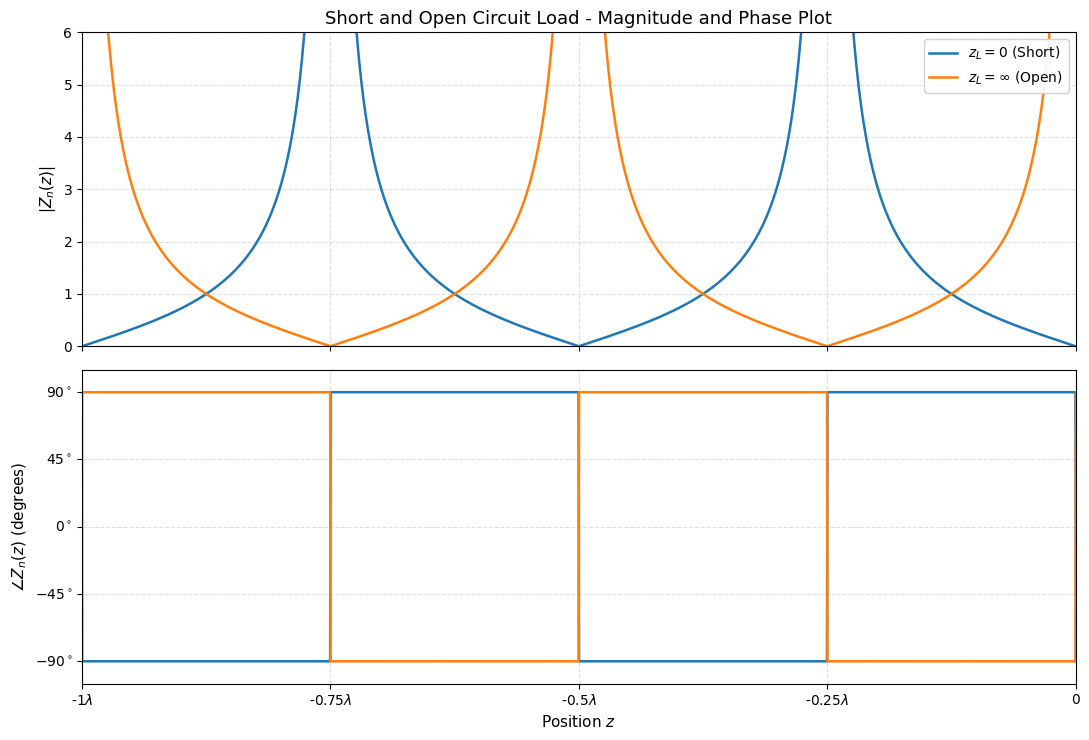

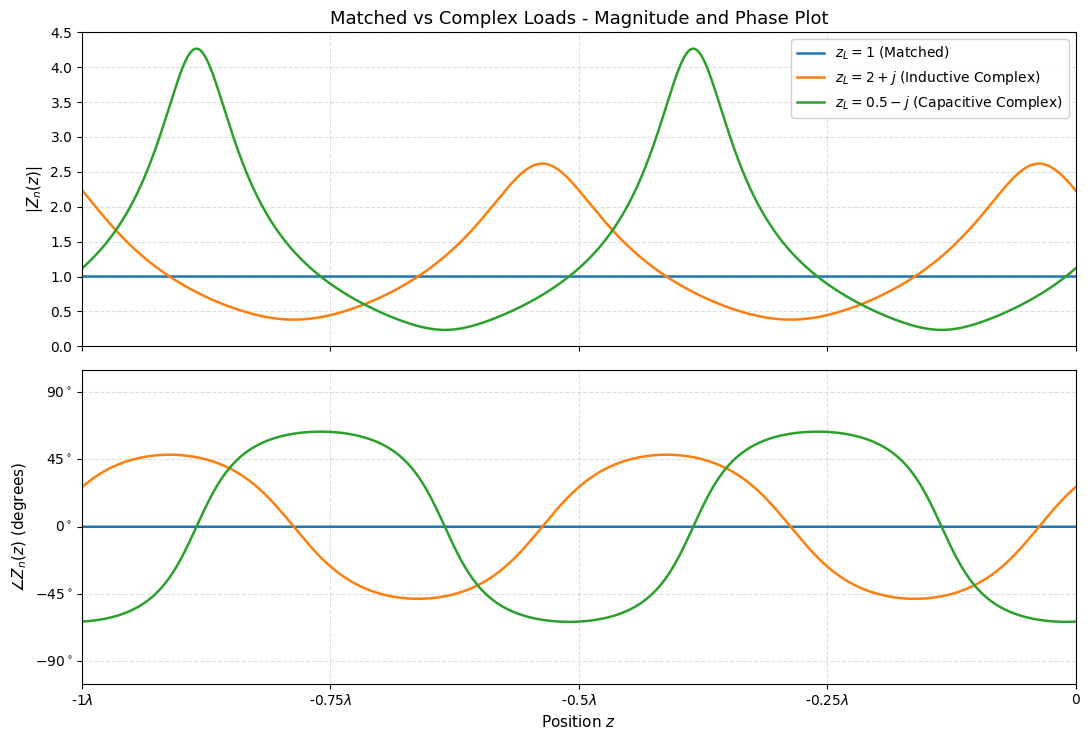

In [31]:
import numpy as np
import matplotlib.pyplot as plt

wavelength = 1e-2 # 1cm
c = 3e8
k = 2*np.pi/wavelength
z = np.linspace(-wavelength*1.5, wavelength*1, 5000)

x_ticks = np.arange(-1.0, 0.01, 0.25)
x_labels = ['0' if np.isclose(val, 0) else f'{val:g}' + r'$\lambda$' for val in x_ticks]
z_lam = z / wavelength

def plot_impedance_group(z_nls, labels, title, mag_ylim, filename):
  z_nls = np.array(z_nls)
  with np.errstate(invalid='ignore'):
    gamma_ls = np.where(np.isinf(z_nls), 1+0j, (z_nls - 1)/(z_nls + 1))

  fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)

  for gamma, label in zip(gamma_ls, labels):
    with np.errstate(divide='ignore', invalid='ignore'):
      num = np.exp(-1j*k*z) + gamma * np.exp(1j*k*z)
      den = np.exp(-1j*k*z) - gamma * np.exp(1j*k*z)
      z_n = num / den

    ax1.plot(z_lam, np.abs(z_n), linewidth=1.8, label=label)
    ax2.plot(z_lam, np.angle(z_n, deg=True), linewidth=1.8, label=label)

  ax1.set_ylim(0, mag_ylim)
  ax1.set_ylabel(r'$|Z_n(z)|$', fontsize=11)
  ax1.set_title(title, fontsize=13)
  ax1.grid(True, linestyle='--', alpha=0.4)
  ax1.legend(loc='upper right', fontsize=10, framealpha=0.9)

  ax2.set_ylim(-105, 105)
  ax2.set_yticks([-90, -45, 0, 45, 90])
  ax2.set_yticklabels([r'$-90^\circ$', r'$-45^\circ$', r'$0^\circ$', r'$45^\circ$', r'$90^\circ$'], fontsize=10)
  ax2.set_ylabel(r'$\angle Z_n(z)$ (degrees)', fontsize=11)
  ax2.set_xlabel(r'Position $z$', fontsize=11)
  ax2.set_xticks(x_ticks)
  ax2.set_xticklabels(x_labels, fontsize=10)
  ax2.set_xlim(-1.0, 0.0)
  ax2.grid(True, linestyle='--', alpha=0.4)

  plt.tight_layout()
  fig.savefig(filename, format='svg', bbox_inches='tight')

# Figure 2: Short and Open Circuit Load
plot_impedance_group(
    z_nls=[0, np.inf],
    labels=[r'$z_L = 0$ (Short)', r'$z_L = \infty$ (Open)'],
    title='Short and Open Circuit Load - Magnitude and Phase Plot',
    mag_ylim=6,
    filename='figure2.svg'
)

# Figure 3: Matched vs Complex Loads
plot_impedance_group(
    z_nls=[1+0j, 2+1j, 0.5-1j],
    labels=[
        r'$z_L = 1$ (Matched)',
        r'$z_L = 2 + j$ (Inductive Complex)',
        r'$z_L = 0.5 - j$ (Capacitive Complex)'
    ],
    title='Matched vs Complex Loads - Magnitude and Phase Plot',
    mag_ylim=4.5,
    filename='figure3.svg'
)

plt.show()
